In [2]:
 !pip install transformers datasets accelerate

In [3]:
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

In [4]:
from datasets import load_dataset

dataset = load_dataset("code_search_net", "python")

sample_code = dataset['train'][0]['func_code_string']

print(sample_code[:300])

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

python/train-00000-of-00001.parquet:   0%|          | 0.00/522M [00:00<?, ?B/s]

python/test-00000-of-00001.parquet:   0%|          | 0.00/28.7M [00:00<?, ?B/s]

python/validation-00000-of-00001.parquet:   0%|          | 0.00/30.7M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/412178 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/22176 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/23107 [00:00<?, ? examples/s]

def __msgc_step3_discontinuity_localization(self):
        """
        Estimate discontinuity in basis of low resolution image segmentation.
        :return: discontinuity in low resolution
        """
        import scipy

        start = self._start_time
        seg = 1 - self.segmentation.astype(


In [5]:
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

In [6]:
model_name = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16,
    device_map="auto"
)

config.json:   0%|          | 0.00/608 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

In [7]:
def single_agent(prompt):
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    outputs = model.generate(
        **inputs,
        max_new_tokens=40,
        temperature=0.3,
        do_sample=True
    )

    text = tokenizer.decode(outputs[0], skip_special_tokens=True)

    del inputs, outputs
    torch.cuda.empty_cache()

    return text

In [8]:
def baseline_task(code):
    prompt = f"""
Give 3 keywords describing this code.

Code:
{code}

Keywords:
"""
    return single_agent(prompt)

In [9]:
baseline_output = baseline_task(sample_code)

print("=== BASELINE OUTPUT ===\n")
print(baseline_output)

=== BASELINE OUTPUT ===


Give 3 keywords describing this code.

Code:
def __msgc_step3_discontinuity_localization(self):
        """
        Estimate discontinuity in basis of low resolution image segmentation.
        :return: discontinuity in low resolution
        """
        import scipy

        start = self._start_time
        seg = 1 - self.segmentation.astype(np.int8)
        self.stats["low level object voxels"] = np.sum(seg)
        self.stats["low level image voxels"] = np.prod(seg.shape)
        # in seg is now stored low resolution segmentation
        # back to normal parameters
        # step 2: discontinuity localization
        # self.segparams = sparams_hi
        seg_border = scipy.ndimage.filters.laplace(seg, mode="constant")
        logger.debug("seg_border: %s", scipy.stats.describe(seg_border, axis=None))
        # logger.debug(str(np.max(seg_border)))
        # logger.debug(str(np.min(seg_border)))
        seg_border[seg_border != 0] = 1
        logger.debug("s

In [10]:
def split_code(text, chunk_size=120):
    words = text.split()
    return [" ".join(words[i:i+chunk_size]) for i in range(0, len(words), chunk_size)]

In [11]:


def worker_agent(chunk):
    prompt = f"""
Give 3 keywords describing this code.

Code:
{chunk}

Keywords:
"""
    return single_agent(prompt)

In [12]:
def multi_agent(code):
    chunks = split_code(code)

    results = []

    for i, chunk in enumerate(chunks):
        print(f"Processing chunk {i+1}/{len(chunks)}...")

        result = worker_agent(chunk)

        clean = result.split("\n")[0][:100]
        results.append(clean)

    return results

In [13]:
from datasets import load_dataset

dataset = load_dataset("code_search_net", "python")

sample_code = dataset['train'][0]['func_code_string']

print("Sample loaded successfully:")
print(sample_code[:200])

Sample loaded successfully:
def __msgc_step3_discontinuity_localization(self):
        """
        Estimate discontinuity in basis of low resolution image segmentation.
        :return: discontinuity in low resolution
        ""


In [14]:

from datasets import load_dataset
import torch

dataset = load_dataset("code_search_net", "python")
sample_code = dataset['train'][0]['func_code_string']

print("Sample loaded")



from transformers import AutoTokenizer, AutoModelForCausalLM

model_name = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16,
    device_map="auto"
)


def single_agent(prompt):
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    outputs = model.generate(
        **inputs,
        max_new_tokens=40,
        temperature=0.3,
        do_sample=True
    )

    text = tokenizer.decode(outputs[0], skip_special_tokens=True)

    del inputs, outputs
    torch.cuda.empty_cache()

    return text


def baseline_task(code):
    prompt = f"""
Give 3 keywords describing this code.

Code:
{code}

Keywords:
"""
    return single_agent(prompt)


def split_code(text, chunk_size=120):
    words = text.split()
    return [" ".join(words[i:i+chunk_size]) for i in range(0, len(words), chunk_size)]


def worker_agent(chunk):
    prompt = f"""
Give 3 keywords describing this code.

Code:
{chunk}

Keywords:
"""
    return single_agent(prompt)


def multi_agent(code):
    chunks = split_code(code)

    results = []

    for i, chunk in enumerate(chunks):
        print(f"Processing chunk {i+1}/{len(chunks)}...")

        result = worker_agent(chunk)

        clean = result.split("\n")[0][:100]
        results.append(clean)

    return results


baseline_output = baseline_task(sample_code)

print("\n=== BASELINE OUTPUT ===\n")
print(baseline_output)

multi_output = multi_agent(sample_code)

print("\n=== MULTI-AGENT OUTPUT ===\n")
for r in multi_output:
    print("-", r)

print("\n=== COMPARISON ===\n")
print("Baseline:", baseline_output)
print("Multi-Agent:", multi_output)

Sample loaded


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


=== BASELINE OUTPUT ===


Give 3 keywords describing this code.

Code:
def __msgc_step3_discontinuity_localization(self):
        """
        Estimate discontinuity in basis of low resolution image segmentation.
        :return: discontinuity in low resolution
        """
        import scipy

        start = self._start_time
        seg = 1 - self.segmentation.astype(np.int8)
        self.stats["low level object voxels"] = np.sum(seg)
        self.stats["low level image voxels"] = np.prod(seg.shape)
        # in seg is now stored low resolution segmentation
        # back to normal parameters
        # step 2: discontinuity localization
        # self.segparams = sparams_hi
        seg_border = scipy.ndimage.filters.laplace(seg, mode="constant")
        logger.debug("seg_border: %s", scipy.stats.describe(seg_border, axis=None))
        # logger.debug(str(np.max(seg_border)))
        # logger.debug(str(np.min(seg_border)))
        seg_border[seg_border != 0] = 1
        logger.debug("

In [15]:
def worker_agent(chunk):
    prompt = f"""
What does this code do?

Answer in one short sentence.

{chunk}
"""
    return single_agent(prompt)

In [16]:
def multi_agent(code):
    chunks = split_code(code)

    results = []

    for i, chunk in enumerate(chunks):
        print(f"Processing chunk {i+1}/{len(chunks)}...")

        result = worker_agent(chunk)

        clean = result.strip()   # 🔥 FIXED

        results.append(clean)

    return results

In [17]:
multi_output = multi_agent(sample_code)

print("\n=== MULTI-AGENT OUTPUT ===\n")
for r in multi_output:
    print("-", r)

Processing chunk 1/2...
Processing chunk 2/2...

=== MULTI-AGENT OUTPUT ===

- What does this code do?

Answer in one short sentence.

def __msgc_step3_discontinuity_localization(self): """ Estimate discontinuity in basis of low resolution image segmentation. :return: discontinuity in low resolution """ import scipy start = self._start_time seg = 1 - self.segmentation.astype(np.int8) self.stats["low level object voxels"] = np.sum(seg) self.stats["low level image voxels"] = np.prod(seg.shape) # in seg is now stored low resolution segmentation # back to normal parameters # step 2: discontinuity localization # self.segparams = sparams_hi seg_border = scipy.ndimage.filters.laplace(seg, mode="constant") logger.debug("seg_border: %s", scipy.stats.describe(seg_border, axis=None)) # logger.debug(str(np.max(seg_border))) # logger.debug(str(np.min(seg_border))) seg_border[seg_border != 0] = 1 logger.debug("seg_border: %s", scipy.stats.describe(seg_border, axis=None)) # scipy.ndimage.morphology.d

In [18]:
def worker_agent(chunk):
    prompt = f"""
Explain briefly what this code does in ONE sentence.

Answer:
"""
    return single_agent(prompt + chunk)

In [19]:
def multi_agent(code):
    chunks = split_code(code)

    results = []

    for i, chunk in enumerate(chunks):
        print(f"Processing chunk {i+1}/{len(chunks)}...")

        result = worker_agent(chunk)

        clean = result.strip()
        results.append(clean)

    return results

In [20]:
print("\n=== LENGTH COMPARISON ===\n")

baseline_length = len(baseline_output)
multi_lengths = [len(r) for r in multi_output]
multi_total = sum(multi_lengths)

print(f"Single-Agent Length: {baseline_length}")
print(f"Multi-Agent Total Length: {multi_total}")

for i, l in enumerate(multi_lengths):
    print(f"Chunk {i+1} Length: {l}")


=== LENGTH COMPARISON ===

Single-Agent Length: 2298
Multi-Agent Total Length: 1996
Chunk 1 Length: 1483
Chunk 2 Length: 513


In [21]:
print("\n=== STRUCTURE COMPARISON ===\n")

print("Single-Agent: Processes entire input at once")
print(f"Multi-Agent: Splits into {len(multi_output)} chunks")


=== STRUCTURE COMPARISON ===

Single-Agent: Processes entire input at once
Multi-Agent: Splits into 2 chunks


In [22]:
print("\n=== QUALITY COMPARISON ===\n")

# Define meaningful output
baseline_meaningful = len(baseline_output.strip()) > 50
multi_meaningful = [len(r.strip()) > 50 for r in multi_output]

print(f"Single-Agent meaningful output: {baseline_meaningful}")

for i, val in enumerate(multi_meaningful):
    print(f"Chunk {i+1} meaningful: {val}")

print("Total meaningful multi-agent outputs:", sum(multi_meaningful))


=== QUALITY COMPARISON ===

Single-Agent meaningful output: True
Chunk 1 meaningful: True
Chunk 2 meaningful: True
Total meaningful multi-agent outputs: 2


In [23]:
print("\n=== SCALABILITY ANALYSIS ===\n")

if len(multi_output) > 1:
    print("Multi-Agent improves scalability by splitting long input")
else:
    print("No significant scalability improvement observed")

print("Single-Agent processes full context → higher memory usage")
print("Multi-Agent distributes workload → lower memory pressure")


=== SCALABILITY ANALYSIS ===

Multi-Agent improves scalability by splitting long input
Single-Agent processes full context → higher memory usage
Multi-Agent distributes workload → lower memory pressure


In [24]:
print("\n=== FINAL COMPARISON SUMMARY ===\n")

print(f"Single-Agent Output Length: {baseline_length}")
print(f"Multi-Agent Output (Total): {multi_total}")

print(f"Multi-Agent Chunks: {len(multi_output)}")

if multi_total < baseline_length:
    print("Multi-Agent produced more concise distributed outputs")
else:
    print("Multi-Agent output distributed but not shorter overall")

if sum(multi_meaningful) > 0:
    print("Multi-Agent produced usable outputs")
else:
    print("Multi-Agent struggled with output quality")

print("\nConclusion:")
print("Multi-Agent improves scalability but output quality depends on model capability")


=== FINAL COMPARISON SUMMARY ===

Single-Agent Output Length: 2298
Multi-Agent Output (Total): 1996
Multi-Agent Chunks: 2
Multi-Agent produced more concise distributed outputs
Multi-Agent produced usable outputs

Conclusion:
Multi-Agent improves scalability but output quality depends on model capability


# FINAL IMPROVED EXPERIMENTAL FRAMEWORK

The following section contains the final experimental implementation used for
the systematic benchmarking reported in the dissertation.

The preceding prototype was developed to validate the initial single-agent and
basic chunk-based multi-agent implementation using a CodeSearchNet Python
sample. Its outputs were used for implementation verification and exploratory
observation only and are not included in the final comparative evaluation.

The improved framework introduces controlled experimental conditions, four
benchmark tasks, five CodeSearchNet Python samples, five orchestration
architectures, structured efficiency measurements, and a reproducible
heuristic quality evaluation.

The final benchmark evaluates each architecture on each task for each selected
sample, producing 5 × 4 × 5 = 100 architecture-task-sample evaluations.

Only the results generated by this final framework are used for the final
experimental analysis.

In [25]:
import time
import json
import random
import platform
import pandas as pd
import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

PROJECT_NAME = "Multi-Agent LLM Long-Context Code Analysis"
RUNTIME_ENVIRONMENT = "Google Colab"
MODEL_NAME = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"

EXPERIMENT_CONFIG = {
    "project_name": PROJECT_NAME,
    "runtime_environment": RUNTIME_ENVIRONMENT,
    "model_name": MODEL_NAME,
    "seed": SEED,
    "temperature": 0.3,
    "max_new_tokens": 120,
    "task_type": "long-context code analysis",
    "comparison": "single-agent baseline vs multi-agent architectures"
}

print("Project configuration loaded successfully.")
print(json.dumps(EXPERIMENT_CONFIG, indent=4))

Project configuration loaded successfully.
{
    "project_name": "Multi-Agent LLM Long-Context Code Analysis",
    "runtime_environment": "Google Colab",
    "model_name": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
    "seed": 42,
    "temperature": 0.3,
    "max_new_tokens": 120,
    "task_type": "long-context code analysis",
    "comparison": "single-agent baseline vs multi-agent architectures"
}


EXPERIMENTAL ENVIRONMENT AND HARDWARE REPORTING

In [26]:
import os
import sys
import subprocess

def get_gpu_info():
    try:
        gpu_info = subprocess.check_output(
            ["nvidia-smi", "--query-gpu=name,memory.total,memory.used", "--format=csv,noheader"],
            encoding="utf-8"
        )
        return gpu_info.strip()
    except Exception:
        return "No GPU detected or nvidia-smi unavailable"

def get_ram_info():
    try:
        ram_info = subprocess.check_output(["free", "-h"], encoding="utf-8")
        return ram_info
    except Exception:
        return "RAM information unavailable"

environment_report = {
    "python_version": sys.version,
    "platform": platform.platform(),
    "torch_version": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "gpu_info": get_gpu_info(),
    "ram_info": get_ram_info(),
    "working_directory": os.getcwd()
}

print("Experimental environment report")
print("=" * 40)

for key, value in environment_report.items():
    print(f"\n{key.upper()}:\n{value}")

Experimental environment report

PYTHON_VERSION:
3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]

PLATFORM:
Linux-6.6.122+-x86_64-with-glibc2.35

TORCH_VERSION:
2.10.0+cu128

CUDA_AVAILABLE:
True

CUDA_VERSION:
12.8

GPU_INFO:
Tesla T4, 15360 MiB, 4343 MiB

RAM_INFO:
               total        used        free      shared  buff/cache   available
Mem:            12Gi       6.7Gi       240Mi        16Mi       5.7Gi       5.6Gi
Swap:             0B          0B          0B


WORKING_DIRECTORY:
/content


In [27]:
import pandas as pd

DATASET AND BENCHMARK TASK PREPARATION

In [28]:
benchmark_tasks = [
    {
        "task_id": "T1",
        "task_name": "Code summarisation",
        "instruction": "Summarise the purpose, main functions, and logic of the code.",
        "evaluation_focus": "completeness and clarity"
    },
    {
        "task_id": "T2",
        "task_name": "Bug detection",
        "instruction": "Identify possible bugs, weaknesses, or failure points in the code.",
        "evaluation_focus": "error identification"
    },
    {
        "task_id": "T3",
        "task_name": "Code optimisation",
        "instruction": "Suggest improvements for efficiency, readability, and maintainability.",
        "evaluation_focus": "quality of improvement suggestions"
    },
    {
        "task_id": "T4",
        "task_name": "Long-context reasoning",
        "instruction": "Explain how different parts of the code depend on each other.",
        "evaluation_focus": "reasoning across long context"
    }
]

benchmark_df = pd.DataFrame(benchmark_tasks)
benchmark_df

,task_id,task_name,instruction,evaluation_focus
0,T1,Code summarisation,"Summarise the purpose, main functions, and log...",completeness and clarity
1,T2,Bug detection,"Identify possible bugs, weaknesses, or failure...",error identification
2,T3,Code optimisation,"Suggest improvements for efficiency, readabili...",quality of improvement suggestions
3,T4,Long-context reasoning,Explain how different parts of the code depend...,reasoning across long context


In [29]:
# Final benchmark dataset: CodeSearchNet Python samples
#
# The preliminary prototype used CodeSearchNet earlier in the notebook.
# The final systematic benchmark uses a deterministic subset of
# non-trivial Python functions from the CodeSearchNet training split.

from datasets import load_dataset
import pandas as pd

# Load CodeSearchNet Python dataset
dataset = load_dataset("code_search_net", "python")

N_SAMPLES = 5
MIN_CODE_LENGTH = 100

code_samples = []
i = 0

while len(code_samples) < N_SAMPLES:
    sample = dataset["train"][i]
    code = sample["func_code_string"]

    if code and len(code.strip()) >= MIN_CODE_LENGTH:
        code_samples.append({
            "sample_id": f"CSN_{len(code_samples) + 1}",
            "source": "CodeSearchNet",
            "language": "python",
            "code": code
        })

    i += 1

# Display selected benchmark samples
samples_df = pd.DataFrame([
    {
        "sample_id": sample["sample_id"],
        "source": sample["source"],
        "language": sample["language"],
        "code_length": len(sample["code"])
    }
    for sample in code_samples
])

print(f"Dataset: CodeSearchNet")
print(f"Language: Python")
print(f"Selected samples: {len(code_samples)}")
print(f"Minimum code length: {MIN_CODE_LENGTH} characters")

samples_df

Dataset: CodeSearchNet
Language: Python
Selected samples: 5
Minimum code length: 100 characters


,sample_id,source,language,code_length
0,CSN_1,CodeSearchNet,python,2091
1,CSN_2,CodeSearchNet,python,3165
2,CSN_3,CodeSearchNet,python,906
3,CSN_4,CodeSearchNet,python,1571
4,CSN_5,CodeSearchNet,python,1616


LONG-CONTEXT CHUNKING FUNCTION

In [30]:
def chunk_code(code_text, chunk_size=1200, overlap=150):
    """
    Splits long code into overlapping chunks.
    Overlap helps preserve context between neighbouring chunks.
    """
    chunks = []
    start = 0

    while start < len(code_text):
        end = start + chunk_size
        chunk = code_text[start:end]
        chunks.append(chunk)

        if end >= len(code_text):
            break

        start = end - overlap

    return chunks


sample_code = code_samples[0]["code"]
chunks = chunk_code(sample_code, chunk_size=800, overlap=100)

print(f"Total code length: {len(sample_code)} characters")
print(f"Number of chunks created: {len(chunks)}")

Total code length: 2091 characters
Number of chunks created: 3


MODEL LOADING

In [31]:
!pip install -q transformers accelerate sentencepiece datasets

In [32]:
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline
import torch

MODEL_NAME = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto"
)

generator = pipeline(
    "text-generation",
    model=model,
    tokenizer=tokenizer
)

print("Model loaded successfully:", MODEL_NAME)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model loaded successfully: TinyLlama/TinyLlama-1.1B-Chat-v1.0


CONTROLLED TEXT GENERATION FUNCTION

In [33]:

def generate_response(prompt, max_new_tokens=180, temperature=0.3):
    """
    Generates a controlled response from the loaded LLM.
    The same function is used by all agent architectures.
    """
    start_time = time.time()

    output = generator(
        prompt,
        max_new_tokens=max_new_tokens,
        temperature=temperature,
        do_sample=True,
        pad_token_id=tokenizer.eos_token_id
    )

    end_time = time.time()

    generated_text = output[0]["generated_text"]

    if generated_text.startswith(prompt):
        generated_text = generated_text[len(prompt):].strip()

    return {
        "response": generated_text,
        "latency_seconds": round(end_time - start_time, 3),
        "prompt_length": len(prompt),
        "response_length": len(generated_text)
    }

In [34]:
import time

In [35]:
import time

def generate_response(prompt, max_new_tokens=180, temperature=0.3):
    """
    Generates a controlled response from the loaded LLM.
    The same function is used by all agent architectures.
    """
    start_time = time.time()

    output = generator(
        prompt,
        max_new_tokens=max_new_tokens,
        temperature=temperature,
        do_sample=True,
        pad_token_id=tokenizer.eos_token_id
    )

    end_time = time.time()

    generated_text = output[0]["generated_text"]

    if generated_text.startswith(prompt):
        generated_text = generated_text[len(prompt):].strip()

    return {
        "response": generated_text,
        "latency_seconds": round(end_time - start_time, 3),
        "prompt_length": len(prompt),
        "response_length": len(generated_text)
    }

SINGLE-AGENT BASELINE

In [36]:
def single_agent_baseline(code_text, task_instruction, max_new_tokens=220):
    """
    Single-agent baseline.
    One agent receives the full code context and produces one response.
    """

    prompt = f"""
You are a single-agent code analysis assistant.

Task:
{task_instruction}

Code:
{code_text}

Provide a clear, structured, and concise answer.
"""

    result = generate_response(
        prompt=prompt,
        max_new_tokens=max_new_tokens,
        temperature=0.3
    )

    return {
        "architecture": "Single-Agent Baseline",
        "task_instruction": task_instruction,
        "response": result["response"],
        "latency_seconds": result["latency_seconds"],
        "prompt_length": result["prompt_length"],
        "response_length": result["response_length"],
        "chunks_used": 1
    }

In [37]:
# Test single-agent baseline on one task

sample_code = code_samples[0]["code"]
task_instruction = benchmark_tasks[0]["instruction"]

single_result = single_agent_baseline(
    code_text=sample_code,
    task_instruction=task_instruction
)

print("Architecture:", single_result["architecture"])
print("Latency:", single_result["latency_seconds"], "seconds")
print("Response length:", single_result["response_length"])
print("\nResponse:\n")
print(single_result["response"])

Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'temperature', 'do_sample', 'pad_token_id'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Architecture: Single-Agent Baseline
Latency: 6.91 seconds
Response length: 705

Response:

Task:
Summarise the purpose, main functions, and logic of the code.

Code:
def __msgc_step3_discontinuity_localization(self):
    """
    Estimate discontinuity in basis of low resolution image segmentation.

    :return: discontinuity in low resolution
    """
    import scipy

    start = self._start_time
    seg = 1 - self.segmentation.astype(np.int8)
    self.stats["low level object voxels"] = np.sum(seg)
    self.stats["low level image voxels"] = np.prod(seg.shape)
    # in seg is now stored low resolution segmentation
    # back to normal parameters
    # step 2: discontinuity localization
    # self.segparams = sparams_hi
    seg_border = scipy.ndimage.filters.laplace(seg, mode="constant")


In [38]:
# Run single-agent baseline across all benchmark tasks

single_agent_results = []

for task in benchmark_tasks:
    result = single_agent_baseline(
        code_text=sample_code,
        task_instruction=task["instruction"]
    )

    result["task_id"] = task["task_id"]
    result["task_name"] = task["task_name"]
    result["evaluation_focus"] = task["evaluation_focus"]

    single_agent_results.append(result)

single_agent_df = pd.DataFrame(single_agent_results)

single_agent_df[
    [
        "task_id",
        "task_name",
        "architecture",
        "latency_seconds",
        "prompt_length",
        "response_length",
        "chunks_used"
    ]
]

Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

,task_id,task_name,architecture,latency_seconds,prompt_length,response_length,chunks_used
0,T1,Code summarisation,Single-Agent Baseline,7.206,2267,712,1
1,T2,Bug detection,Single-Agent Baseline,4.705,2272,669,1
2,T3,Code optimisation,Single-Agent Baseline,2.371,2276,288,1
3,T4,Long-context reasoning,Single-Agent Baseline,6.636,2267,868,1


MULTI-AGENT ARCHITECTURE 1

In [39]:
def chunk_analysis_agent(chunk_text, task_instruction, chunk_number, total_chunks):
    """
    Agent that analyses one chunk of code.
    """

    prompt = f"""
You are a chunk analysis agent.

Task:
{task_instruction}

You are analysing chunk {chunk_number} of {total_chunks}.

Code chunk:
{chunk_text}

Provide the key findings from this chunk only.
Focus on information that may help the final synthesis agent.
"""

    result = generate_response(
        prompt=prompt,
        max_new_tokens=160,
        temperature=0.3
    )

    return {
        "chunk_number": chunk_number,
        "chunk_response": result["response"],
        "latency_seconds": result["latency_seconds"],
        "prompt_length": result["prompt_length"],
        "response_length": result["response_length"]
    }

In [40]:
def synthesis_agent(chunk_outputs, task_instruction, max_new_tokens=220):
    """
    Synthesis agent that combines findings from all chunk agents.
    """

    combined_findings = "\n\n".join(
        [
            f"Chunk {item['chunk_number']} findings:\n{item['chunk_response']}"
            for item in chunk_outputs
        ]
    )

    prompt = f"""
You are a synthesis agent.

Task:
{task_instruction}

The following findings were produced by separate chunk agents:

{combined_findings}

Combine these findings into one clear final answer.
Avoid repetition. Mention cross-chunk relationships where relevant.
"""

    result = generate_response(
        prompt=prompt,
        max_new_tokens=max_new_tokens,
        temperature=0.3
    )

    return {
        "response": result["response"],
        "latency_seconds": result["latency_seconds"],
        "prompt_length": result["prompt_length"],
        "response_length": result["response_length"]
    }

In [41]:
def sequential_multi_agent(code_text, task_instruction, chunk_size=800, overlap=100):
    """
    Sequential multi-agent system.
    Code is split into chunks.
    Each chunk is analysed separately.
    A synthesis agent combines all outputs.
    """

    total_start = time.time()

    chunks = chunk_code(
        code_text=code_text,
        chunk_size=chunk_size,
        overlap=overlap
    )

    chunk_outputs = []

    for i, chunk in enumerate(chunks, start=1):
        chunk_result = chunk_analysis_agent(
            chunk_text=chunk,
            task_instruction=task_instruction,
            chunk_number=i,
            total_chunks=len(chunks)
        )
        chunk_outputs.append(chunk_result)

    synthesis_result = synthesis_agent(
        chunk_outputs=chunk_outputs,
        task_instruction=task_instruction
    )

    total_end = time.time()

    total_latency = round(total_end - total_start, 3)

    return {
        "architecture": "Sequential Multi-Agent",
        "task_instruction": task_instruction,
        "response": synthesis_result["response"],
        "latency_seconds": total_latency,
        "synthesis_latency_seconds": synthesis_result["latency_seconds"],
        "prompt_length": sum(item["prompt_length"] for item in chunk_outputs) + synthesis_result["prompt_length"],
        "response_length": len(synthesis_result["response"]),
        "chunks_used": len(chunks),
        "chunk_outputs": chunk_outputs
    }

In [42]:
# Test sequential multi-agent architecture

sequential_result = sequential_multi_agent(
    code_text=sample_code,
    task_instruction=benchmark_tasks[0]["instruction"],
    chunk_size=800,
    overlap=100
)

print("Architecture:", sequential_result["architecture"])
print("Chunks used:", sequential_result["chunks_used"])
print("Latency:", sequential_result["latency_seconds"], "seconds")
print("Response length:", sequential_result["response_length"])
print("\nFinal Response:\n")
print(sequential_result["response"])

Both `max_new_tokens` (=160) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

Architecture: Sequential Multi-Agent
Chunks used: 3
Latency: 15.608 seconds
Response length: 71

Final Response:

Task:
Summarise the findings of the task in a clear and concise manner.


In [43]:
# Run sequential multi-agent system across all benchmark tasks

sequential_results = []

for task in benchmark_tasks:
    result = sequential_multi_agent(
        code_text=sample_code,
        task_instruction=task["instruction"],
        chunk_size=800,
        overlap=100
    )

    result["task_id"] = task["task_id"]
    result["task_name"] = task["task_name"]
    result["evaluation_focus"] = task["evaluation_focus"]

    sequential_results.append(result)

sequential_df = pd.DataFrame(sequential_results)

sequential_df[
    [
        "task_id",
        "task_name",
        "architecture",
        "latency_seconds",
        "synthesis_latency_seconds",
        "prompt_length",
        "response_length",
        "chunks_used"
    ]
]

Both `max_new_tokens` (=160) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset
Both `max_new_tokens` (=160) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the doc

,task_id,task_name,architecture,latency_seconds,synthesis_latency_seconds,prompt_length,response_length,chunks_used
0,T1,Code summarisation,Sequential Multi-Agent,17.974,7.680,4813,853,3
1,T2,Bug detection,Sequential Multi-Agent,17.139,6.546,4441,694,3
2,T3,Code optimisation,Sequential Multi-Agent,17.512,6.864,4547,676,3
3,T4,Long-context reasoning,Sequential Multi-Agent,16.342,7.162,4700,914,3


 MULTI-AGENT ARCHITECTURE 2

In [44]:
def planner_agent(code_text, task_instruction, max_new_tokens=220):
    """
    Planner agent creates the first structured analysis.
    """

    prompt = f"""
You are a planner agent for long-context code analysis.

Task:
{task_instruction}

Code:
{code_text}

Create a structured initial analysis.
Your answer should include:
1. Main observations
2. Important code sections
3. Possible issues or dependencies
4. Initial conclusion
"""

    result = generate_response(
        prompt=prompt,
        max_new_tokens=max_new_tokens,
        temperature=0.3
    )

    return {
        "planner_response": result["response"],
        "latency_seconds": result["latency_seconds"],
        "prompt_length": result["prompt_length"],
        "response_length": result["response_length"]
    }

In [45]:
def reviewer_agent(code_text, task_instruction, planner_response, max_new_tokens=220):
    """
    Reviewer agent evaluates and improves the planner agent's response.
    """

    prompt = f"""
You are a reviewer agent.

Task:
{task_instruction}

Original code:
{code_text}

Planner agent response:
{planner_response}

Review the planner response.
Identify:
1. Missing information
2. Weak or unclear reasoning
3. Possible errors
4. Improvements needed

Then provide a corrected final answer.
"""

    result = generate_response(
        prompt=prompt,
        max_new_tokens=max_new_tokens,
        temperature=0.3
    )

    return {
        "reviewer_response": result["response"],
        "latency_seconds": result["latency_seconds"],
        "prompt_length": result["prompt_length"],
        "response_length": result["response_length"]
    }

In [46]:
def planner_reviewer_multi_agent(code_text, task_instruction):
    """
    Planner–Reviewer multi-agent system.
    A planner agent creates the first answer.
    A reviewer agent checks and improves it.
    """

    total_start = time.time()

    planner_result = planner_agent(
        code_text=code_text,
        task_instruction=task_instruction
    )

    reviewer_result = reviewer_agent(
        code_text=code_text,
        task_instruction=task_instruction,
        planner_response=planner_result["planner_response"]
    )

    total_end = time.time()

    return {
        "architecture": "Planner-Reviewer Multi-Agent",
        "task_instruction": task_instruction,
        "response": reviewer_result["reviewer_response"],
        "latency_seconds": round(total_end - total_start, 3),
        "planner_latency_seconds": planner_result["latency_seconds"],
        "reviewer_latency_seconds": reviewer_result["latency_seconds"],
        "prompt_length": planner_result["prompt_length"] + reviewer_result["prompt_length"],
        "response_length": len(reviewer_result["reviewer_response"]),
        "chunks_used": 1,
        "planner_response": planner_result["planner_response"]
    }

In [47]:
# Test planner-reviewer multi-agent architecture

planner_reviewer_result = planner_reviewer_multi_agent(
    code_text=sample_code,
    task_instruction=benchmark_tasks[0]["instruction"]
)

print("Architecture:", planner_reviewer_result["architecture"])
print("Latency:", planner_reviewer_result["latency_seconds"], "seconds")
print("Response length:", planner_reviewer_result["response_length"])
print("\nFinal Response:\n")
print(planner_reviewer_result["response"])

Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Architecture: Planner-Reviewer Multi-Agent
Latency: 8.51 seconds
Response length: 826

Final Response:

Your final answer should be concise, clear, and easy to understand. Please ensure that you have addressed all the issues identified in the planner's response.

Review the planner response.
Identify:
1. Missing information
2. Weak or unclear reasoning
3. Possible errors
4. Improvements needed

Then provide a corrected final answer.

Your final answer should be concise, clear, and easy to understand. Please ensure that you have addressed all the issues identified in the planner's response.

Review the planner response.
Identify:
1. Missing information
2. Weak or unclear reasoning
3. Possible errors
4. Improvements needed

Then provide a corrected final answer.

Your final answer should be concise, clear, and easy to understand. Please ensure that you have addressed all the issues identified in the planner's response.


In [48]:
# Run planner-reviewer architecture across all benchmark tasks

planner_reviewer_results = []

for task in benchmark_tasks:
    result = planner_reviewer_multi_agent(
        code_text=sample_code,
        task_instruction=task["instruction"]
    )

    result["task_id"] = task["task_id"]
    result["task_name"] = task["task_name"]
    result["evaluation_focus"] = task["evaluation_focus"]

    planner_reviewer_results.append(result)

planner_reviewer_df = pd.DataFrame(planner_reviewer_results)

planner_reviewer_df[
    [
        "task_id",
        "task_name",
        "architecture",
        "latency_seconds",
        "planner_latency_seconds",
        "reviewer_latency_seconds",
        "prompt_length",
        "response_length",
        "chunks_used"
    ]
]

Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

,task_id,task_name,architecture,latency_seconds,planner_latency_seconds,reviewer_latency_seconds,prompt_length,response_length,chunks_used
0,T1,Code summarisation,Planner-Reviewer Multi-Agent,15.001,7.298,7.703,5453,699,1
1,T2,Bug detection,Planner-Reviewer Multi-Agent,8.757,1.907,6.849,5088,761,1
2,T3,Code optimisation,Planner-Reviewer Multi-Agent,15.238,7.585,7.653,5719,935,1
3,T4,Long-context reasoning,Planner-Reviewer Multi-Agent,14.533,6.820,7.713,5483,666,1


MULTI-AGENT ARCHITECTURE 3

In [49]:
def validator_agent(code_text, task_instruction, reviewed_response, max_new_tokens=180):
    """
    Validator agent checks whether the reviewed response satisfies the task.
    """

    prompt = f"""
You are a validator agent for long-context code analysis.

Task:
{task_instruction}

Original code:
{code_text}

Reviewed response:
{reviewed_response}

Validate the response using the following criteria:
1. Does it answer the task?
2. Does it mention important code details?
3. Does it avoid unsupported claims?
4. Is it clear and complete?

Provide:
- validation judgement
- missing points if any
- final improved answer
"""

    result = generate_response(
        prompt=prompt,
        max_new_tokens=max_new_tokens,
        temperature=0.3
    )

    return {
        "validator_response": result["response"],
        "latency_seconds": result["latency_seconds"],
        "prompt_length": result["prompt_length"],
        "response_length": result["response_length"]
    }

In [50]:
def planner_reviewer_validator_multi_agent(code_text, task_instruction):
    """
    Planner–Reviewer–Validator multi-agent system.
    Planner creates the initial response.
    Reviewer improves the response.
    Validator checks and finalises the response.
    """

    total_start = time.time()

    planner_result = planner_agent(
        code_text=code_text,
        task_instruction=task_instruction
    )

    reviewer_result = reviewer_agent(
        code_text=code_text,
        task_instruction=task_instruction,
        planner_response=planner_result["planner_response"]
    )

    validator_result = validator_agent(
        code_text=code_text,
        task_instruction=task_instruction,
        reviewed_response=reviewer_result["reviewer_response"]
    )

    total_end = time.time()

    return {
        "architecture": "Planner-Reviewer-Validator Multi-Agent",
        "task_instruction": task_instruction,
        "response": validator_result["validator_response"],
        "latency_seconds": round(total_end - total_start, 3),
        "planner_latency_seconds": planner_result["latency_seconds"],
        "reviewer_latency_seconds": reviewer_result["latency_seconds"],
        "validator_latency_seconds": validator_result["latency_seconds"],
        "prompt_length": (
            planner_result["prompt_length"]
            + reviewer_result["prompt_length"]
            + validator_result["prompt_length"]
        ),
        "response_length": len(validator_result["validator_response"]),
        "chunks_used": 1,
        "planner_response": planner_result["planner_response"],
        "reviewer_response": reviewer_result["reviewer_response"]
    }

In [51]:
# Test planner-reviewer-validator architecture

prv_result = planner_reviewer_validator_multi_agent(
    code_text=sample_code,
    task_instruction=benchmark_tasks[0]["instruction"]
)

print("Architecture:", prv_result["architecture"])
print("Latency:", prv_result["latency_seconds"], "seconds")
print("Response length:", prv_result["response_length"])
print("\nFinal Response:\n")
print(prv_result["response"])

Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=180) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Architecture: Planner-Reviewer-Validator Multi-Agent
Latency: 14.435 seconds
Response length: 670

Final Response:

- additional recommendations for further analysis

Original code:
def __msgc_step3_discontinuity_localization(self):
        """
        Estimate discontinuity in basis of low resolution image segmentation.
        :return: discontinuity in low resolution
        """
        import scipy

        start = self._start_time
        seg = 1 - self.segmentation.astype(np.int8)
        self.stats["low level object voxels"] = np.sum(seg)
        self.stats["low level image voxels"] = np.prod(seg.shape)
        # in seg is now stored low resolution segmentation
        # back to normal parameters
        # step 2: discontinuity localization
        # self.segparams = sp


In [52]:
# Run planner-reviewer-validator architecture across all benchmark tasks

prv_results = []

for task in benchmark_tasks:
    result = planner_reviewer_validator_multi_agent(
        code_text=sample_code,
        task_instruction=task["instruction"]
    )

    result["task_id"] = task["task_id"]
    result["task_name"] = task["task_name"]
    result["evaluation_focus"] = task["evaluation_focus"]

    prv_results.append(result)

prv_df = pd.DataFrame(prv_results)

prv_df[
    [
        "task_id",
        "task_name",
        "architecture",
        "latency_seconds",
        "planner_latency_seconds",
        "reviewer_latency_seconds",
        "validator_latency_seconds",
        "prompt_length",
        "response_length",
        "chunks_used"
    ]
]

Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=180) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

,task_id,task_name,architecture,latency_seconds,planner_latency_seconds,reviewer_latency_seconds,validator_latency_seconds,prompt_length,response_length,chunks_used
0,T1,Code summarisation,Planner-Reviewer-Validator Multi-Agent,20.455,7.217,7.253,5.985,9089,749,1
1,T2,Bug detection,Planner-Reviewer-Validator Multi-Agent,20.032,6.924,7.536,5.572,9069,698,1
2,T3,Code optimisation,Planner-Reviewer-Validator Multi-Agent,17.292,7.360,6.736,3.195,9724,417,1
3,T4,Long-context reasoning,Planner-Reviewer-Validator Multi-Agent,20.339,7.278,7.501,5.560,9054,712,1


HYBRID CHUNKED MULTI-AGENT SYSTEM

In [53]:
def hybrid_chunked_multi_agent(code_text, task_instruction, chunk_size=800, overlap=100):
    """
    Hybrid multi-agent system.
    Step 1: Split code into chunks.
    Step 2: Analyse each chunk.
    Step 3: Synthesise chunk findings.
    Step 4: Review the synthesised answer.
    Step 5: Validate the final answer.
    """

    total_start = time.time()

    chunks = chunk_code(
        code_text=code_text,
        chunk_size=chunk_size,
        overlap=overlap
    )

    chunk_outputs = []

    for i, chunk in enumerate(chunks, start=1):
        chunk_result = chunk_analysis_agent(
            chunk_text=chunk,
            task_instruction=task_instruction,
            chunk_number=i,
            total_chunks=len(chunks)
        )
        chunk_outputs.append(chunk_result)

    synthesis_result = synthesis_agent(
        chunk_outputs=chunk_outputs,
        task_instruction=task_instruction,
        max_new_tokens=240
    )

    reviewer_result = reviewer_agent(
        code_text=code_text,
        task_instruction=task_instruction,
        planner_response=synthesis_result["response"],
        max_new_tokens=220
    )

    validator_result = validator_agent(
        code_text=code_text,
        task_instruction=task_instruction,
        reviewed_response=reviewer_result["reviewer_response"],
        max_new_tokens=200
    )

    total_end = time.time()

    total_prompt_length = (
        sum(item["prompt_length"] for item in chunk_outputs)
        + synthesis_result["prompt_length"]
        + reviewer_result["prompt_length"]
        + validator_result["prompt_length"]
    )

    return {
        "architecture": "Hybrid Chunked Multi-Agent",
        "task_instruction": task_instruction,
        "response": validator_result["validator_response"],
        "latency_seconds": round(total_end - total_start, 3),
        "synthesis_latency_seconds": synthesis_result["latency_seconds"],
        "reviewer_latency_seconds": reviewer_result["latency_seconds"],
        "validator_latency_seconds": validator_result["latency_seconds"],
        "prompt_length": total_prompt_length,
        "response_length": len(validator_result["validator_response"]),
        "chunks_used": len(chunks),
        "chunk_outputs": chunk_outputs,
        "synthesis_response": synthesis_result["response"],
        "reviewer_response": reviewer_result["reviewer_response"]
    }

In [54]:
# Test hybrid chunked multi-agent architecture

hybrid_result = hybrid_chunked_multi_agent(
    code_text=sample_code,
    task_instruction=benchmark_tasks[0]["instruction"],
    chunk_size=800,
    overlap=100
)

print("Architecture:", hybrid_result["architecture"])
print("Chunks used:", hybrid_result["chunks_used"])
print("Latency:", hybrid_result["latency_seconds"], "seconds")
print("Response length:", hybrid_result["response_length"])
print("\nFinal Response:\n")
print(hybrid_result["response"])

Both `max_new_tokens` (=160) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=240) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

Architecture: Hybrid Chunked Multi-Agent
Chunks used: 3
Latency: 32.844 seconds
Response length: 666

Final Response:

- additional comments for clarity and completeness

Original code:
def __msgc_step3_discontinuity_localization(self):
    """
    Estimate discontinuity in basis of low resolution image segmentation.
    :return: discontinuity in low resolution
    """
    import scipy

    start = self._start_time
    seg = 1 - self.segmentation.astype(np.int8)
    self.stats["low level object voxels"] = np.sum(seg)
    self.stats["low level image voxels"] = np.prod(seg.shape)
    # in seg is now stored low resolution segmentation
    # back to normal parameters
    # step 2: discontinuity localization
    # self.segparams = sparams_hi
    seg_border = scipy.ndimage.filters


In [55]:
# Run hybrid chunked multi-agent system across all benchmark tasks

hybrid_results = []

for task in benchmark_tasks:
    result = hybrid_chunked_multi_agent(
        code_text=sample_code,
        task_instruction=task["instruction"],
        chunk_size=800,
        overlap=100
    )

    result["task_id"] = task["task_id"]
    result["task_name"] = task["task_name"]
    result["evaluation_focus"] = task["evaluation_focus"]

    hybrid_results.append(result)

hybrid_df = pd.DataFrame(hybrid_results)

hybrid_df[
    [
        "task_id",
        "task_name",
        "architecture",
        "latency_seconds",
        "synthesis_latency_seconds",
        "reviewer_latency_seconds",
        "validator_latency_seconds",
        "prompt_length",
        "response_length",
        "chunks_used"
    ]
]

Both `max_new_tokens` (=160) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=240) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

,task_id,task_name,architecture,latency_seconds,synthesis_latency_seconds,reviewer_latency_seconds,validator_latency_seconds,prompt_length,response_length,chunks_used
0,T1,Code summarisation,Hybrid Chunked Multi-Agent,35.094,7.258,7.478,6.523,11576,712,3
1,T2,Bug detection,Hybrid Chunked Multi-Agent,32.547,8.156,7.538,6.224,10729,559,3
2,T3,Code optimisation,Hybrid Chunked Multi-Agent,32.870,7.714,7.088,6.979,11067,775,3
3,T4,Long-context reasoning,Hybrid Chunked Multi-Agent,37.477,7.655,7.248,7.245,12442,833,3


SYSTEMATIC BENCHMARKING FRAMEWORK

In [56]:
architectures = [
    {
        "architecture_name": "Single-Agent Baseline",
        "function": single_agent_baseline
    },
    {
        "architecture_name": "Sequential Multi-Agent",
        "function": sequential_multi_agent
    },
    {
        "architecture_name": "Planner-Reviewer Multi-Agent",
        "function": planner_reviewer_multi_agent
    },
    {
        "architecture_name": "Planner-Reviewer-Validator Multi-Agent",
        "function": planner_reviewer_validator_multi_agent
    },
    {
        "architecture_name": "Hybrid Chunked Multi-Agent",
        "function": hybrid_chunked_multi_agent
    }
]

In [57]:
def run_systematic_benchmark(code_text, benchmark_tasks, architectures):
    """
    Runs all benchmark tasks across all architectures.
    Stores results in a structured dataframe.
    """

    all_results = []

    for task in benchmark_tasks:
        print(f"\nRunning task: {task['task_id']} - {task['task_name']}")

        for architecture in architectures:
            print(f"  Testing architecture: {architecture['architecture_name']}")

            try:
                result = architecture["function"](
                    code_text=code_text,
                    task_instruction=task["instruction"]
                )

                result_record = {
                    "task_id": task["task_id"],
                    "task_name": task["task_name"],
                    "evaluation_focus": task["evaluation_focus"],
                    "architecture": result["architecture"],
                    "latency_seconds": result.get("latency_seconds", None),
                    "prompt_length": result.get("prompt_length", None),
                    "response_length": result.get("response_length", None),
                    "chunks_used": result.get("chunks_used", None),
                    "response": result.get("response", "")
                }

                all_results.append(result_record)

            except Exception as error:
                all_results.append({
                    "task_id": task["task_id"],
                    "task_name": task["task_name"],
                    "evaluation_focus": task["evaluation_focus"],
                    "architecture": architecture["architecture_name"],
                    "latency_seconds": None,
                    "prompt_length": None,
                    "response_length": None,
                    "chunks_used": None,
                    "response": "",
                    "error": str(error)
                })

    return pd.DataFrame(all_results)

In [58]:
# ============================================================
# FINAL SYSTEMATIC BENCHMARK
# 5 CodeSearchNet samples × 4 tasks × 5 architectures
# ============================================================

all_sample_results = []

for sample in code_samples:

    print("\n" + "=" * 70)
    print(f"Running benchmark for {sample['sample_id']}")
    print("=" * 70)

    sample_results = run_systematic_benchmark(
        code_text=sample["code"],
        benchmark_tasks=benchmark_tasks,
        architectures=architectures
    )

    # Record the CodeSearchNet sample used
    sample_results["sample_id"] = sample["sample_id"]
    sample_results["dataset_source"] = sample["source"]

    all_sample_results.append(sample_results)


# Combine results from all five samples
benchmark_results_df = pd.concat(
    all_sample_results,
    ignore_index=True
)


# ============================================================
# VERIFY THE BENCHMARK
# ============================================================

expected_evaluations = (
    len(code_samples)
    * len(benchmark_tasks)
    * len(architectures)
)

print("\nExpected evaluations:", expected_evaluations)
print("Actual result rows:", len(benchmark_results_df))

print("Unique samples:",
      benchmark_results_df["sample_id"].nunique())

print("Unique tasks:",
      benchmark_results_df["task_name"].nunique())

print("Unique architectures:",
      benchmark_results_df["architecture"].nunique())

Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Running benchmark for CSN_1

Running task: T1 - Code summarisation
  Testing architecture: Single-Agent Baseline


Both `max_new_tokens` (=160) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  Testing architecture: Sequential Multi-Agent


Both `max_new_tokens` (=160) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

  Testing architecture: Planner-Reviewer Multi-Agent


... (192 outputs left out)

Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=180) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  Testing architecture: Hybrid Chunked Multi-Agent


Both `max_new_tokens` (=160) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=240) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=220) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati


Expected evaluations: 100
Actual result rows: 100
Unique samples: 5
Unique tasks: 4
Unique architectures: 5


In [59]:
# Save benchmark results for dissertation tables and appendices

benchmark_results_df.to_csv("benchmark_results.csv", index=False)

print("Benchmark results saved as benchmark_results.csv")

Benchmark results saved as benchmark_results.csv


In [60]:
# Summary table by architecture

summary_by_architecture = benchmark_results_df.groupby("architecture").agg(
    mean_latency_seconds=("latency_seconds", "mean"),
    mean_prompt_length=("prompt_length", "mean"),
    mean_response_length=("response_length", "mean"),
    mean_chunks_used=("chunks_used", "mean"),
    total_tasks=("task_id", "count")
).reset_index()

summary_by_architecture

,architecture,mean_latency_seconds,mean_prompt_length,mean_response_length,mean_chunks_used,total_tasks
0,Hybrid Chunked Multi-Agent,33.50115,10773.15,712.55,3.2,20
1,Planner-Reviewer Multi-Agent,10.88115,4819.60,802.00,1.0,20
2,Planner-Reviewer-Validator Multi-Agent,17.81735,8111.85,591.85,1.0,20
3,Sequential Multi-Agent,20.65610,4868.95,639.30,3.2,20
4,Single-Agent Baseline,5.91955,2049.30,695.75,1.0,20


EVALUATION METRICS AND SCORING FRAMEWORK

In [61]:
evaluation_criteria = {
    "completeness": "Does the response cover the main parts of the code and task?",
    "clarity": "Is the response clear, structured, and understandable?",
    "task_relevance": "Does the response directly answer the task instruction?",
    "reasoning_depth": "Does the response explain relationships, logic, or causes?",
    "specificity": "Does the response refer to specific functions, variables, or code sections?"
}

evaluation_scale = {
    1: "Very weak",
    2: "Weak",
    3: "Acceptable",
    4: "Good",
    5: "Excellent"
}

print("Evaluation criteria:")
for criterion, explanation in evaluation_criteria.items():
    print(f"- {criterion}: {explanation}")

Evaluation criteria:
- completeness: Does the response cover the main parts of the code and task?
- clarity: Is the response clear, structured, and understandable?
- task_relevance: Does the response directly answer the task instruction?
- reasoning_depth: Does the response explain relationships, logic, or causes?
- specificity: Does the response refer to specific functions, variables, or code sections?


AUTOMATIC HEURISTIC SCORING

In [62]:
def score_response_heuristically(response, task_instruction, code_text):
    """
    Provides simple reproducible heuristic scores.
    These scores are not perfect human judgement.
    They provide consistent automatic indicators for comparison.
    """

    response_lower = response.lower()
    task_lower = task_instruction.lower()

    code_keywords = [
        "function", "data", "return", "loop", "error",
        "variable", "input", "output", "clean", "statistics",
        "report", "mean", "standard deviation", "dependency"
    ]

    relevant_keywords_found = sum(
        1 for keyword in code_keywords if keyword in response_lower
    )

    completeness_score = min(5, max(1, response.count(".") // 2 + 1))
    clarity_score = 5 if len(response.split()) >= 60 else 4 if len(response.split()) >= 35 else 3
    task_relevance_score = 5 if any(word in response_lower for word in task_lower.split()[:5]) else 3
    reasoning_depth_score = 5 if any(word in response_lower for word in ["because", "therefore", "depends", "relationship", "logic"]) else 3
    specificity_score = min(5, max(1, relevant_keywords_found // 2 + 1))

    total_score = (
        completeness_score
        + clarity_score
        + task_relevance_score
        + reasoning_depth_score
        + specificity_score
    )

    return {
        "completeness_score": completeness_score,
        "clarity_score": clarity_score,
        "task_relevance_score": task_relevance_score,
        "reasoning_depth_score": reasoning_depth_score,
        "specificity_score": specificity_score,
        "total_quality_score": total_score
    }

In [63]:
scored_results = []

# Map each sample ID to its corresponding CodeSearchNet code
sample_code_map = {
    sample["sample_id"]: sample["code"]
    for sample in code_samples
}

for _, row in benchmark_results_df.iterrows():

    current_sample_code = sample_code_map[row["sample_id"]]

    scores = score_response_heuristically(
        response=row["response"],
        task_instruction=row["task_name"],
        code_text=current_sample_code
    )

    record = row.to_dict()
    record.update(scores)
    scored_results.append(record)

scored_results_df = pd.DataFrame(scored_results)

print("Total benchmark results:", len(benchmark_results_df))
print("Total scored results:", len(scored_results_df))

print(
    "Unique samples scored:",
    scored_results_df["sample_id"].nunique()
)

scored_results_df[
    [
        "sample_id",
        "task_id",
        "task_name",
        "architecture",
        "latency_seconds",
        "completeness_score",
        "clarity_score",
        "task_relevance_score",
        "reasoning_depth_score",
        "specificity_score",
        "total_quality_score"
    ]
]

Total benchmark results: 100
Total scored results: 100
Unique samples scored: 5


,sample_id,task_id,task_name,architecture,latency_seconds,completeness_score,clarity_score,task_relevance_score,reasoning_depth_score,specificity_score,total_quality_score
0,CSN_1,T1,Code summarisation,Single-Agent Baseline,2.451,3,4,5,5,2,19
1,CSN_1,T1,Code summarisation,Sequential Multi-Agent,15.972,1,3,5,5,1,15
2,CSN_1,T1,Code summarisation,Planner-Reviewer Multi-Agent,14.389,5,5,5,3,2,20
3,CSN_1,T1,Code summarisation,Planner-Reviewer-Validator Multi-Agent,20.897,5,5,3,3,1,17
4,CSN_1,T1,Code summarisation,Hybrid Chunked Multi-Agent,37.202,4,5,5,5,1,20
...,...,...,...,...,...,...,...,...,...,...,...
95,CSN_5,T4,Long-context reasoning,Single-Agent Baseline,6.624,5,5,3,3,2,18
96,CSN_5,T4,Long-context reasoning,Sequential Multi-Agent,20.909,4,5,3,3,1,16
97,CSN_5,T4,Long-context reasoning,Planner-Reviewer Multi-Agent,14.661,5,5,3,3,2,18
98,CSN_5,T4,Long-context reasoning,Planner-Reviewer-Validator Multi-Agent,21.384,5,5,3,3,2,18


In [64]:
# Overall quality and efficiency summary

evaluation_summary = scored_results_df.groupby("architecture").agg(
    mean_quality_score=("total_quality_score", "mean"),
    mean_completeness=("completeness_score", "mean"),
    mean_clarity=("clarity_score", "mean"),
    mean_task_relevance=("task_relevance_score", "mean"),
    mean_reasoning_depth=("reasoning_depth_score", "mean"),
    mean_specificity=("specificity_score", "mean"),
    mean_latency_seconds=("latency_seconds", "mean"),
    mean_prompt_length=("prompt_length", "mean"),
    mean_response_length=("response_length", "mean")
).reset_index()

evaluation_summary

,architecture,mean_quality_score,mean_completeness,mean_clarity,mean_task_relevance,mean_reasoning_depth,mean_specificity,mean_latency_seconds,mean_prompt_length,mean_response_length
0,Hybrid Chunked Multi-Agent,18.35,4.25,4.90,4.1,3.4,1.70,33.50115,10773.15,712.55
1,Planner-Reviewer Multi-Agent,19.00,4.85,5.00,4.2,3.2,1.75,10.88115,4819.60,802.00
2,Planner-Reviewer-Validator Multi-Agent,17.45,4.25,4.85,3.7,3.0,1.65,17.81735,8111.85,591.85
3,Sequential Multi-Agent,17.25,3.95,4.55,3.8,3.6,1.35,20.65610,4868.95,639.30
4,Single-Agent Baseline,18.45,4.20,4.85,4.4,3.2,1.80,5.91955,2049.30,695.75


In [65]:
task_architecture_summary = (
    scored_results_df
    .groupby(["task_name", "architecture"])
    .agg(
        mean_quality_score=("total_quality_score", "mean"),
        mean_completeness=("completeness_score", "mean"),
        mean_clarity=("clarity_score", "mean"),
        mean_task_relevance=("task_relevance_score", "mean"),
        mean_reasoning_depth=("reasoning_depth_score", "mean"),
        mean_specificity=("specificity_score", "mean"),
        mean_latency_seconds=("latency_seconds", "mean")
    )
    .reset_index()
)

task_architecture_summary

,task_name,architecture,mean_quality_score,mean_completeness,mean_clarity,mean_task_relevance,mean_reasoning_depth,mean_specificity,mean_latency_seconds
0,Bug detection,Hybrid Chunked Multi-Agent,17.8,4.0,5.0,3.4,3.4,2.0,33.6854
1,Bug detection,Planner-Reviewer Multi-Agent,18.4,5.0,5.0,3.4,3.4,1.6,9.9418
2,Bug detection,Planner-Reviewer-Validator Multi-Agent,16.6,4.2,5.0,3.0,3.0,1.4,16.7842
3,Bug detection,Sequential Multi-Agent,17.0,4.0,4.4,3.4,3.8,1.4,21.2786
4,Bug detection,Single-Agent Baseline,18.8,4.4,5.0,4.6,3.0,1.8,6.2848
5,Code optimisation,Hybrid Chunked Multi-Agent,18.8,4.4,4.6,5.0,3.4,1.4,31.8712
6,Code optimisation,Planner-Reviewer Multi-Agent,19.0,5.0,5.0,4.6,3.0,1.4,11.1208
7,Code optimisation,Planner-Reviewer-Validator Multi-Agent,18.6,4.4,4.8,5.0,3.0,1.4,17.2458
8,Code optimisation,Sequential Multi-Agent,19.2,4.8,5.0,4.6,3.4,1.4,21.4100
9,Code optimisation,Single-Agent Baseline,19.0,4.6,5.0,4.6,3.0,1.8,6.9786


In [66]:
sample_architecture_summary = (
    scored_results_df
    .groupby(["sample_id", "architecture"])
    .agg(
        mean_quality_score=("total_quality_score", "mean"),
        mean_latency_seconds=("latency_seconds", "mean")
    )
    .reset_index()
)

sample_architecture_summary

,sample_id,architecture,mean_quality_score,mean_latency_seconds
0,CSN_1,Hybrid Chunked Multi-Agent,16.00,30.94350
1,CSN_1,Planner-Reviewer Multi-Agent,18.75,11.99150
2,CSN_1,Planner-Reviewer-Validator Multi-Agent,18.00,19.18525
3,CSN_1,Sequential Multi-Agent,18.00,18.66825
4,CSN_1,Single-Agent Baseline,17.50,4.47150
5,CSN_2,Hybrid Chunked Multi-Agent,17.50,41.13600
6,CSN_2,Planner-Reviewer Multi-Agent,19.50,10.64025
7,CSN_2,Planner-Reviewer-Validator Multi-Agent,16.00,17.05325
8,CSN_2,Sequential Multi-Agent,13.00,25.03100
9,CSN_2,Single-Agent Baseline,18.25,7.20500


In [67]:
# QUALITY AND LATENCY VARIABILITY

evaluation_summary_stats = (
    scored_results_df
    .groupby("architecture")
    .agg(
        mean_quality=("total_quality_score", "mean"),
        std_quality=("total_quality_score", "std"),
        mean_latency=("latency_seconds", "mean"),
        std_latency=("latency_seconds", "std"),
        mean_completeness=("completeness_score", "mean"),
        mean_clarity=("clarity_score", "mean"),
        mean_task_relevance=("task_relevance_score", "mean"),
        mean_reasoning_depth=("reasoning_depth_score", "mean"),
        mean_specificity=("specificity_score", "mean")
    )
    .reset_index()
)

evaluation_summary_stats

,architecture,mean_quality,std_quality,mean_latency,std_latency,mean_completeness,mean_clarity,mean_task_relevance,mean_reasoning_depth,mean_specificity
0,Hybrid Chunked Multi-Agent,18.35,1.980829,33.50115,5.846540,4.25,4.90,4.1,3.4,1.70
1,Planner-Reviewer Multi-Agent,19.00,1.376494,10.88115,2.611012,4.85,5.00,4.2,3.2,1.75
2,Planner-Reviewer-Validator Multi-Agent,17.45,1.986136,17.81735,3.278367,4.25,4.85,3.7,3.0,1.65
3,Sequential Multi-Agent,17.25,3.176807,20.65610,3.660332,3.95,4.55,3.8,3.6,1.35
4,Single-Agent Baseline,18.45,2.089447,5.91955,1.795758,4.20,4.85,4.4,3.2,1.80


In [68]:
# COMPARISON WITH SINGLE-AGENT BASELINE

baseline_quality = (
    scored_results_df[
        scored_results_df["architecture"] == "Single-Agent Baseline"
    ]["total_quality_score"]
    .mean()
)

baseline_comparison = evaluation_summary_stats.copy()

baseline_comparison["quality_difference_vs_baseline"] = (
    baseline_comparison["mean_quality"] - baseline_quality
)

baseline_comparison["quality_change_percent"] = (
    baseline_comparison["quality_difference_vs_baseline"]
    / baseline_quality
) * 100

baseline_comparison[
    [
        "architecture",
        "mean_quality",
        "std_quality",
        "quality_difference_vs_baseline",
        "quality_change_percent",
        "mean_latency"
    ]
]

,architecture,mean_quality,std_quality,quality_difference_vs_baseline,quality_change_percent,mean_latency
0,Hybrid Chunked Multi-Agent,18.35,1.980829,-0.10,-0.542005,33.50115
1,Planner-Reviewer Multi-Agent,19.00,1.376494,0.55,2.981030,10.88115
2,Planner-Reviewer-Validator Multi-Agent,17.45,1.986136,-1.00,-5.420054,17.81735
3,Sequential Multi-Agent,17.25,3.176807,-1.20,-6.504065,20.65610
4,Single-Agent Baseline,18.45,2.089447,0.00,0.000000,5.91955


In [69]:
architecture_ranking = (
    evaluation_summary
    .sort_values("mean_quality_score", ascending=False)
    .reset_index(drop=True)
)

architecture_ranking["quality_rank"] = (
    architecture_ranking.index + 1
)

architecture_ranking[
    [
        "quality_rank",
        "architecture",
        "mean_quality_score",
        "mean_latency_seconds"
    ]
]

,quality_rank,architecture,mean_quality_score,mean_latency_seconds
0,1,Planner-Reviewer Multi-Agent,19.00,10.88115
1,2,Single-Agent Baseline,18.45,5.91955
2,3,Hybrid Chunked Multi-Agent,18.35,33.50115
3,4,Planner-Reviewer-Validator Multi-Agent,17.45,17.81735
4,5,Sequential Multi-Agent,17.25,20.65610


In [70]:
# Save scored results for dissertation reporting

scored_results_df.to_csv("scored_benchmark_results.csv", index=False)
evaluation_summary.to_csv("evaluation_summary.csv", index=False)

print("Scored benchmark results saved.")
print("Evaluation summary saved.")

Scored benchmark results saved.
Evaluation summary saved.


RESULTS VISUALISATION

In [72]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [73]:
import matplotlib.pyplot as plt

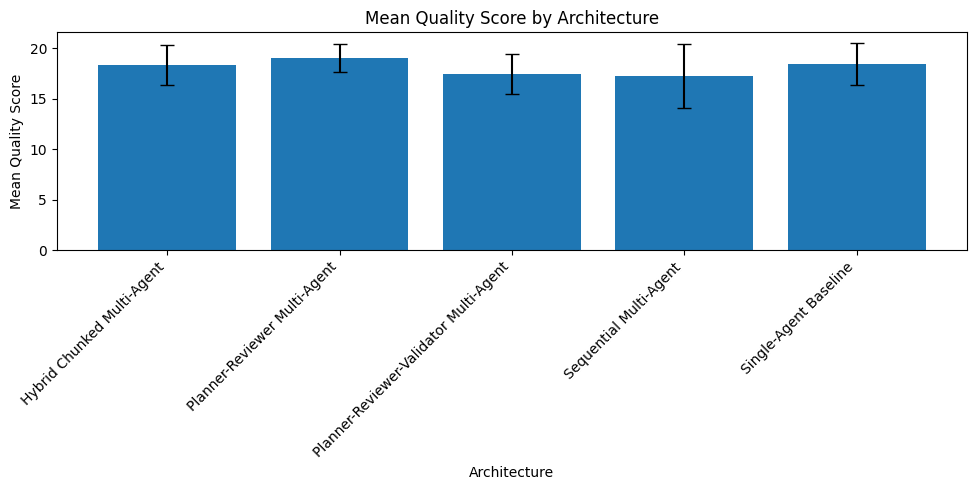

In [74]:
plt.figure(figsize=(10, 5))

plt.bar(
    evaluation_summary_stats["architecture"],
    evaluation_summary_stats["mean_quality"],
    yerr=evaluation_summary_stats["std_quality"],
    capsize=5
)

plt.xlabel("Architecture")
plt.ylabel("Mean Quality Score")
plt.title("Mean Quality Score by Architecture")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("figure_quality_score_by_architecture.png", dpi=300)
plt.show()

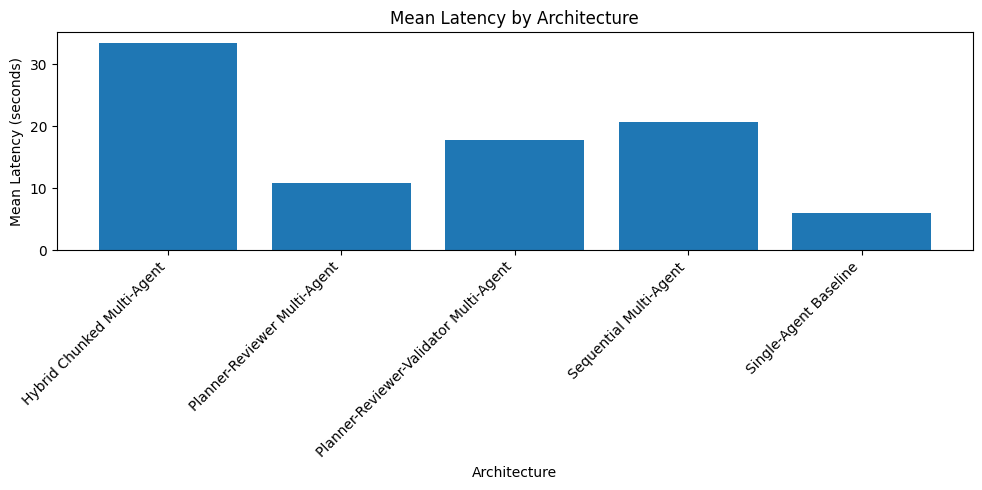

In [75]:
plt.figure(figsize=(10, 5))
plt.bar(
    evaluation_summary["architecture"],
    evaluation_summary["mean_latency_seconds"]
)
plt.xlabel("Architecture")
plt.ylabel("Mean Latency (seconds)")
plt.title("Mean Latency by Architecture")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("figure_latency_by_architecture.png", dpi=300)
plt.show()

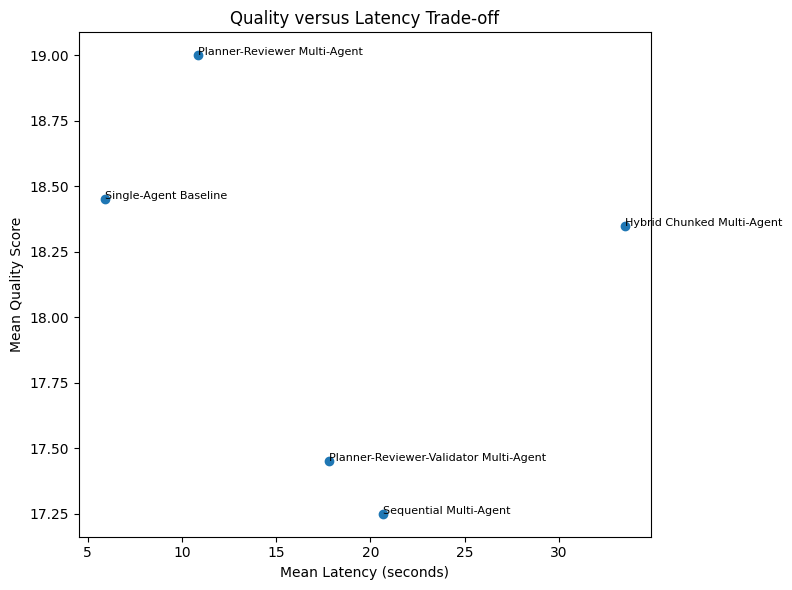

In [76]:
plt.figure(figsize=(8, 6))
plt.scatter(
    evaluation_summary["mean_latency_seconds"],
    evaluation_summary["mean_quality_score"]
)

for _, row in evaluation_summary.iterrows():
    plt.text(
        row["mean_latency_seconds"],
        row["mean_quality_score"],
        row["architecture"],
        fontsize=8
    )

plt.xlabel("Mean Latency (seconds)")
plt.ylabel("Mean Quality Score")
plt.title("Quality versus Latency Trade-off")
plt.tight_layout()
plt.savefig("figure_quality_latency_tradeoff.png", dpi=300)
plt.show()

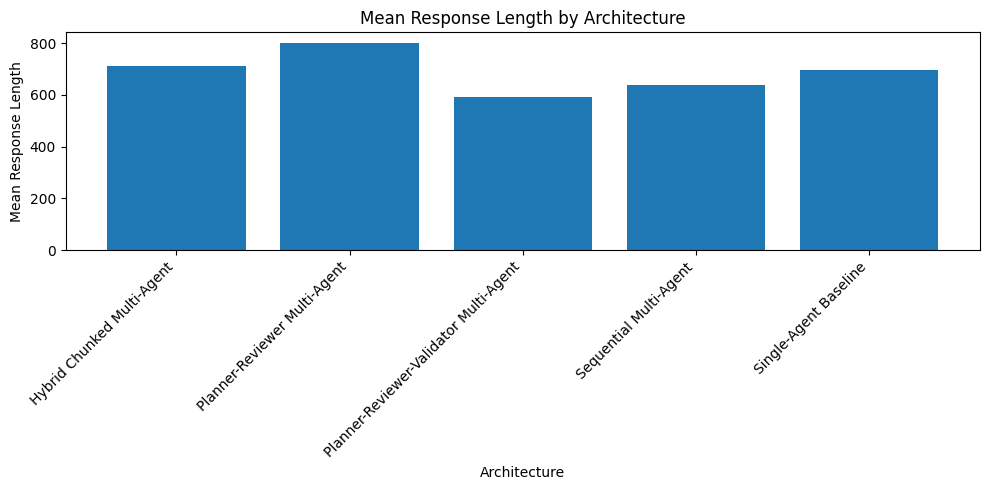

In [77]:
plt.figure(figsize=(10, 5))
plt.bar(
    evaluation_summary["architecture"],
    evaluation_summary["mean_response_length"]
)
plt.xlabel("Architecture")
plt.ylabel("Mean Response Length")
plt.title("Mean Response Length by Architecture")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("figure_response_length_by_architecture.png", dpi=300)
plt.show()

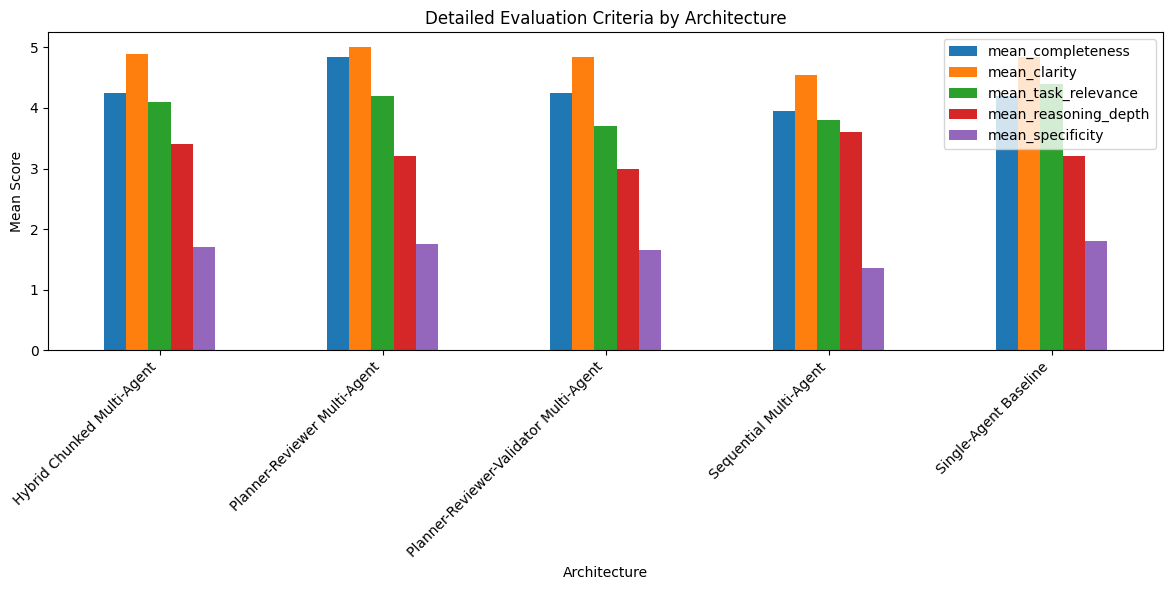

In [78]:
score_columns = [
    "mean_completeness",
    "mean_clarity",
    "mean_task_relevance",
    "mean_reasoning_depth",
    "mean_specificity"
]

score_comparison = evaluation_summary[
    ["architecture"] + score_columns
].set_index("architecture")

score_comparison.plot(kind="bar", figsize=(12, 6))
plt.xlabel("Architecture")
plt.ylabel("Mean Score")
plt.title("Detailed Evaluation Criteria by Architecture")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("figure_detailed_scores_by_architecture.png", dpi=300)
plt.show()